-0.14868702651903803
-0.021611925576285468
-0.03415644136897904
-0.14868702651903803
0.0065632458233890216
-0.021611925576285468
0.0028234086242299797
-0.03415644136897904
0.00892857142857143


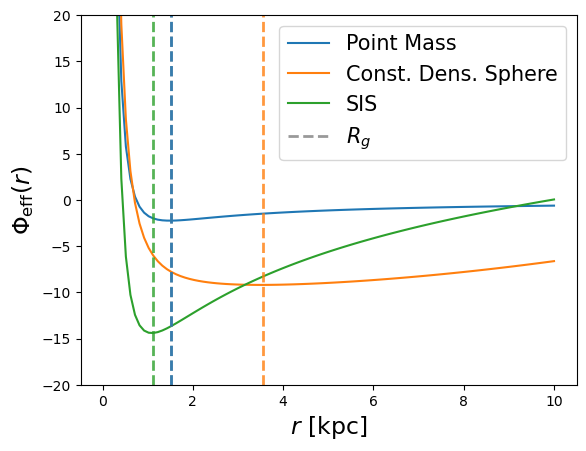

In [77]:

import astropy.units as u
import astropy.constants as cst
import numpy as np
import matplotlib.pyplot as plt

M = 1E11 * u.M_sun
R = 10 * u.kpc

# Constant-density sphere
rho_0 = 1E12 * u.M_sun / (4/3 * np.pi * R**3)

# SIS density normalization
C_SIS = 1E12 * u.M_sun / (100 * u.kpc)

def Phi_eff(r, phi, L_z=8e2*u.kpc*u.km/u.s):
    print(np.median(L_z**2/(2*r**2)/np.median(phi(r))).decompose())
    return phi(r) + L_z**2/(2*r**2)

def Phi_point_mass(r):
    return -cst.G*M/r

def Phi_Const_Sphere(r):
    return -2*np.pi*cst.G*rho_0*(R**2-r**2/3)

def Phi_SIS(r):
    v_c = np.sqrt(4*np.pi*cst.G*C_SIS)
    return v_c**2*np.log((r/(10*u.kpc)).decompose().value)

rs = np.linspace(0.01,10,100)*u.kpc
ax = plt.subplot(111)
ax.plot(rs, Phi_eff(rs, Phi_point_mass),
         label="Point Mass")
ax.plot(rs, Phi_eff(rs, Phi_Const_Sphere),
         label="Const. Dens. Sphere")
ax.plot(rs, Phi_eff(rs, Phi_SIS),
         label="SIS")
colors = [line.get_color() for line in ax.lines]

for i, phi in enumerate([Phi_point_mass, Phi_Const_Sphere, Phi_SIS]):
    y = Phi_eff(rs, phi)

    idx = np.argmin(y)
    R_g = rs[idx]
    print(rs[0]/R_g)
    if i==0:
        ax.axvline(R_g.value, color="grey",ls="--", lw=2, alpha=0.8, label="$R_g$")
    ax.axvline(R_g.value, color=colors[i],ls="--", lw=2, alpha=0.8)

ax.set_ylabel(r"$\Phi_\mathrm{eff}(r)$", fontsize=17)
ax.set_xlabel(r"$r$ [kpc]", fontsize=17)
#ax.set_yscale("symlog")
ax.set_ylim(-20,20)
ax.legend(fontsize=15)
plt.savefig("q1.pdf")
plt.show()


-0.021611925576285468
-0.021611925576285468
0.0028234086242299797
3.5418181818181815 kpc


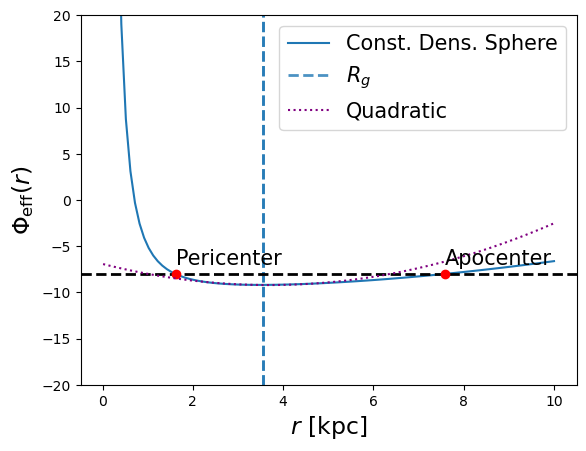

In [100]:

import astropy.units as u
import astropy.constants as cst
import numpy as np
import matplotlib.pyplot as plt

M = 1E11 * u.M_sun
R = 10 * u.kpc

# Constant-density sphere
rho_0 = 1E12 * u.M_sun / (4/3 * np.pi * R**3)

# SIS density normalization
C_SIS = 1E12 * u.M_sun / (100 * u.kpc)

def Phi_eff(r, phi, L_z=8e2*u.kpc*u.km/u.s):
    print(np.median(L_z**2/(2*r**2)/np.median(phi(r))).decompose())
    return phi(r) + L_z**2/(2*r**2)

def Phi_point_mass(r):
    return -cst.G*M/r

def Phi_Const_Sphere(r):
    return -2*np.pi*cst.G*rho_0*(R**2-r**2/3)

def Phi_SIS(r):
    v_c = np.sqrt(4*np.pi*cst.G*C_SIS)
    return v_c**2*np.log((r/(10*u.kpc)).decompose().value)

rs = np.linspace(0.01,10,100)*u.kpc
ax = plt.subplot(111)
ax.plot(rs, Phi_eff(rs, Phi_Const_Sphere),
         label="Const. Dens. Sphere")
colors = [line.get_color() for line in ax.lines]

y = Phi_eff(rs, Phi_Const_Sphere)

idx = np.argmin(y)
R_g = rs[idx]
print(rs[0]/R_g)
if i==0:
    ax.axvline(R_g.value, color=colors[0],ls="--", lw=2, alpha=0.8, label="$R_g$")
ax.axvline(R_g.value, color=colors[0],ls="--", lw=2, alpha=0.8)
ax.axhline(-8, color="black",ls="--", lw=2, alpha=1)

idx_min = np.argmin(y.value)
idx_left = np.argmin((y.value[:idx_min] + 8)**2)
idx_right = idx_min + np.argmin((y.value[idx_min:] + 8)**2)
r = rs[idx_left]
plt.plot(r,y[idx_left],marker="o",color="red")
plt.text(r.value, y[idx_left].value+1, "Pericenter", fontsize=15)
r = rs[idx_right]
plt.plot(r,y[idx_right],marker="o",color="red")
plt.text(r.value, y[idx_left].value+1, "Apocenter", fontsize=15)

def quadratic(x,a,b,c):
    return c+a*(x-R_g.value)+b*(x-R_g.value)**2

from scipy.optimize import curve_fit
print(R_g)
mask = (np.array(rs.value) > 2) & (np.array(rs.value) < 5)
res = curve_fit(quadratic, rs.value[mask], y.value[mask], p0=(0.1,0.1,-10))
plt.plot(rs,quadratic(rs.value, *res[0]),marker="None",ls=":",color="purple", label="Quadratic")
ax.set_ylabel(r"$\Phi_\mathrm{eff}(r)$", fontsize=17)
ax.set_xlabel(r"$r$ [kpc]", fontsize=17)
#ax.set_yscale("symlog")
ax.set_ylim(-20,20)
ax.legend(fontsize=15)
plt.savefig("q1_4.pdf")
plt.show()


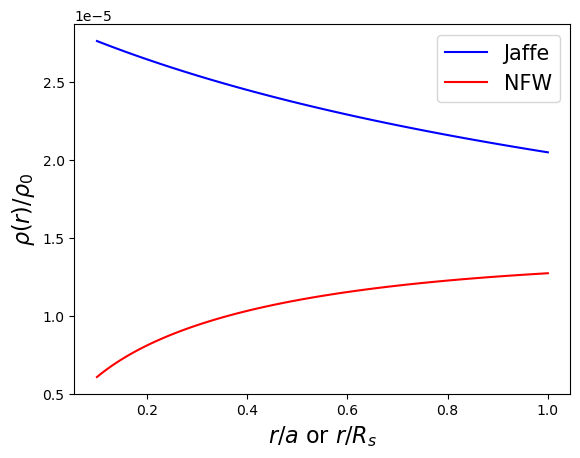

0.25
0.25


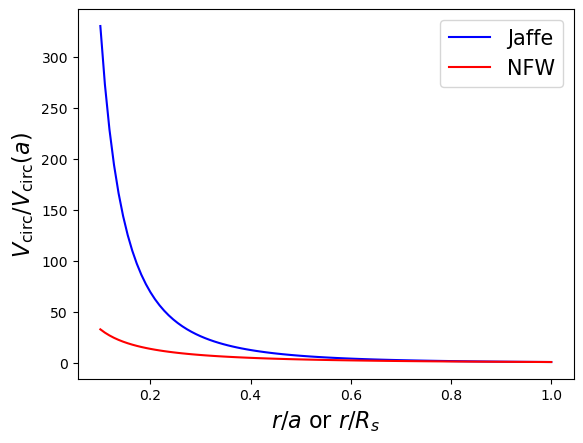

In [113]:
import astropy.units as u
import astropy.constants as cst
import numpy as np
import matplotlib.pyplot as plt

a = 1
rho_0 = 1

def Jaffe_pot(r):
    x = r/a
    return 4*np.pi*cst.G*rho_0*a**2*np.log(x/(1+x))
def Jaffe_density(r):
    x = r/a
    return rho_0/(x**2*(1+x)**2)
def Jaffe_v_circ(r):
    dphi_dr = 4*np.pi*cst.G*rho_0 *a**2 * a/(r*(r+a))
    return np.sqrt(r*dphi_dr)

R_s = 1
def NFW_pot(r):
    return -4*np.pi*cst.G*rho_0*R_s**3*np.log(1+r/R_s)/r
def NFW_density(r):
    return rho_0/ (r/R_s*(1+r/R_s)**2) 
def NFW_V_circ(r):
    return np.sqrt(4*np.pi*cst.G*rho_0*R_s**3/r * (np.log(1+r/R_s) - r/(r+R_s)) )

rs = np.linspace(0.1,a,100)
plt.plot(rs, Jaffe_v_circ(rs),ls="-",marker="None",color="blue",label="Jaffe")
plt.plot(rs, NFW_V_circ(rs),ls="-",marker="None",color="red",label="NFW")
plt.xlabel(r"$r/a$ or $r/R_s$", fontsize=16)
plt.ylabel(r"$\rho(r)/\rho_0$", fontsize=16)
plt.legend(fontsize=15)
plt.savefig("q3_2_density.pdf")
plt.show()
print(NFW_density(rs)[-1])
print(Jaffe_density(rs)[-1])
plt.plot(rs, 4*Jaffe_density(rs),ls="-",marker="None",color="blue",label="Jaffe")
plt.plot(rs, 4*NFW_density(rs),ls="-",marker="None",color="red",label="NFW")
plt.xlabel(r"$r/a$ or $r/R_s$", fontsize=16)
plt.ylabel(r"$V_\mathrm{circ}/V_\mathrm{circ}(a)$", fontsize=16)
plt.legend(fontsize=15)
plt.savefig("q3_2_V_circ.pdf")
plt.show()
